# Lucrare de Laborator: Autoencoder simplu și Variational Autoencoder (VAE) pe MNIST

## Obiective

Construim un autoencoder simplu pentru reconstrucția imaginilor MNIST și un VAE care învață un spațiu latent probabilistic din care putem genera imagini noi.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)


## Încărcarea și preprocesarea datelor

Imaginile sunt normalizate în [0, 1] și transformate din 28x28 în vectori de 784 de pixeli. Din setul de antrenare separăm un set de validare; setul de test rămâne neatins până la evaluarea finală. Pentru autoencodere, imaginea originală este și targetul.

In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

X_train_norm = X_train.astype("float32") / 255.0
X_test_norm = X_test.astype("float32") / 255.0
X_train_flat = X_train_norm.reshape((-1, 784))
X_test_flat = X_test_norm.reshape((-1, 784))

# Validare separată din train: testul nu este folosit pentru alegeri de model.
validation_size = 6000
X_train_fit = X_train_flat[:-validation_size]
X_val_flat = X_train_flat[-validation_size:]
y_train_fit = y_train[:-validation_size]
y_val = y_train[-validation_size:]

print("X_train:", X_train_fit.shape)
print("X_val:", X_val_flat.shape)
print("X_test:", X_test_flat.shape)
print("Interval pixeli:", X_train_flat.min(), X_train_flat.max())

X_train: (54000, 784)
X_val: (6000, 784)
X_test: (10000, 784)
Interval pixeli: 0.0 1.0


## 1. Autoencoder simplu

Encoderul comprimă imaginea într-un vector latent de 32 de dimensiuni, iar decoderul reconstruiește cei 784 de pixeli.

In [3]:
input_dim = 784
latent_dim = 32

ae_input = keras.Input(shape=(input_dim,), name="input_image")
ae_encoded = layers.Dense(128, activation="relu")(ae_input)
ae_latent = layers.Dense(latent_dim, activation="relu", name="latent_vector")(ae_encoded)
ae_decoded = layers.Dense(128, activation="relu")(ae_latent)
ae_output = layers.Dense(input_dim, activation="sigmoid", name="reconstructed_image")(ae_decoded)

autoencoder = keras.Model(ae_input, ae_output, name="simple_autoencoder")
encoder = keras.Model(ae_input, ae_latent, name="simple_encoder")
autoencoder.compile(optimizer="adam", loss="binary_crossentropy")
autoencoder.summary()

history_ae = autoencoder.fit(
    X_train_fit, X_train_fit, epochs=10, batch_size=256,
    validation_data=(X_val_flat, X_val_flat), verbose=1
)

Model: "simple_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_image (Dense)     │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2383 - val_loss: 0.1568
Epoch 2/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1409 - val_loss: 0.1282
Epoch 3/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1214 - val_loss: 0.1157
Epoch 4/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1123 - val_loss: 0.1086
Epoch 5/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1062 - val_loss: 0.1039
Epoch 6/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1024 - val_loss: 0.1009
Epoch 7/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0996 - val_loss: 0.0985
Epoch 8/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0974 - val_loss: 0.0967
Epoch 9/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0957 - val_loss: 0.0953
Epoch 10/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0944 - val_loss: 0.0942


### Reconstrucții produse de autoencoder

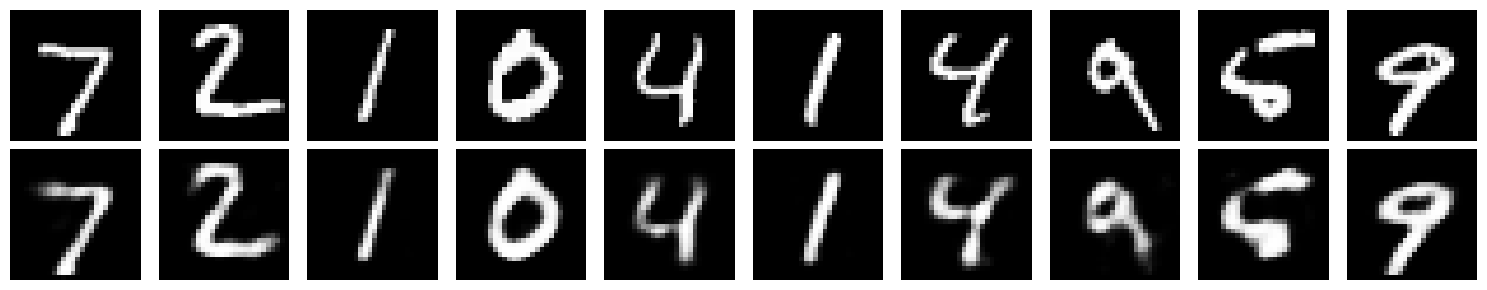

Dimensiunea codului latent AE: (1, 32)


In [4]:
ae_reconstructed = autoencoder.predict(X_test_flat, verbose=0)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    axes[0, i].imshow(X_test_flat[i].reshape(28, 28), cmap="gray")
    axes[1, i].imshow(ae_reconstructed[i].reshape(28, 28), cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstruit")
plt.tight_layout()
plt.show()

print("Dimensiunea codului latent AE:", encoder.predict(X_test_flat[:1], verbose=0).shape)


## 2. Variational Autoencoder (VAE)

Encoderul produce media \(\mu\) și log-varianța \(\log\sigma^2\). Eșantionarea folosește reparameterization trick:
\[
z = \mu + \exp(0.5\log\sigma^2)\,\epsilon, \quad \epsilon\sim\mathcal N(0,I).
\]

Reconstrucția este binary cross-entropy mediată pe cei 784 de pixeli. Pentru aceeași scară, KL este media pe exemple a sumei pe dimensiunile latente, împărțită la 784. Greutatea beta este crescută gradual (KL annealing), reducând riscul de posterior collapse.

In [5]:
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

vae_latent_dim = 10
vae_input = keras.Input(shape=(784,), name="vae_input")
vae_hidden = layers.Dense(256, activation="relu")(vae_input)
z_mean = layers.Dense(vae_latent_dim, name="z_mean")(vae_hidden)
z_log_var = layers.Dense(vae_latent_dim, name="z_log_var")(vae_hidden)
z = Sampling()([z_mean, z_log_var])
vae_encoder = keras.Model(vae_input, [z_mean, z_log_var, z], name="vae_encoder")

z_input = keras.Input(shape=(vae_latent_dim,), name="z_sampling")
decoder_hidden = layers.Dense(256, activation="relu")(z_input)
decoder_output = layers.Dense(784, activation="sigmoid")(decoder_hidden)
vae_decoder = keras.Model(z_input, decoder_output, name="vae_decoder")

class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs); self.encoder_model = encoder; self.decoder_model = decoder
        self.beta = tf.Variable(0.0, trainable=False, dtype=tf.float32, name="kl_beta")
    def call(self, inputs, training=False):
        _, _, sample = self.encoder_model(inputs, training=training)
        return self.decoder_model(sample, training=training)
    def compute_vae_losses(self, data, training):
        mean, log_var, sample = self.encoder_model(data, training=training)
        reconstruction = self.decoder_model(sample, training=training)
        reconstruction_loss = tf.reduce_mean(keras.losses.binary_crossentropy(data, reconstruction))
        kl_per_example = 0.5 * tf.reduce_sum(tf.square(mean) + tf.exp(log_var) - 1.0 - log_var, axis=1)
        kl_loss = tf.reduce_mean(kl_per_example) / tf.cast(input_dim, tf.float32)
        return reconstruction_loss + self.beta * kl_loss, reconstruction_loss, kl_loss
    def train_step(self, data):
        data = data[0] if isinstance(data, tuple) else data
        with tf.GradientTape() as tape:
            total, rec, kl = self.compute_vae_losses(data, training=True)
        gradients = tape.gradient(total, self.trainable_weights)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_weights))
        return {"loss": total, "reconstruction_loss": rec, "kl_loss": kl}
    def test_step(self, data):
        data = data[0] if isinstance(data, tuple) else data
        total, rec, kl = self.compute_vae_losses(data, training=False)
        return {"loss": total, "reconstruction_loss": rec, "kl_loss": kl}

class KLAnnealing(keras.callbacks.Callback):
    def __init__(self, model, warmup_epochs=10, max_beta=1.0):
        super().__init__(); self.model_ref = model; self.warmup_epochs = warmup_epochs; self.max_beta = max_beta
    def on_epoch_begin(self, epoch, logs=None):
        beta = self.max_beta * min(1.0, (epoch + 1) / self.warmup_epochs)
        self.model_ref.beta.assign(beta); print(f"\nKL beta = {beta:.3f}")

vae = VAE(vae_encoder, vae_decoder, name="variational_autoencoder")
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4))
history_vae = vae.fit(
    X_train_fit, epochs=30, batch_size=128,
    validation_data=(X_val_flat,), callbacks=[KLAnnealing(vae, warmup_epochs=10)], verbose=1
)


KL beta = 0.100
Epoch 1/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 0.1116 - loss: 0.2561 - reconstruction_loss: 0.2449 - val_kl_loss: 0.0751 - val_loss: 0.2658 - val_reconstruction_loss: 0.2583

KL beta = 0.200
Epoch 2/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - kl_loss: 0.0706 - loss: 0.2063 - reconstruction_loss: 0.1922 - val_kl_loss: 0.0583 - val_loss: 0.2121 - val_reconstruction_loss: 0.2005

KL beta = 0.300
Epoch 3/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - kl_loss: 0.0485 - loss: 0.1914 - reconstruction_loss: 0.1769 - val_kl_loss: 0.0425 - val_loss: 0.1954 - val_reconstruction_loss: 0.1826

KL beta = 0.400
Epoch 4/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - kl_loss: 0.0390 - loss: 0.1834 - reconstruction_loss: 0.1678 - val_kl_loss: 0.0348 - val_loss: 0.1872 - val_reconstruction_loss: 0.1732

KL beta = 0.500
Epoch 5/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - kl_loss: 0.0336 - loss: 0.1787 - reconstruction_loss: 0.1619 - val_kl_loss: 0.0299 - val_loss: 0.1829

### Reconstrucții VAE și distribuția în spațiul latent

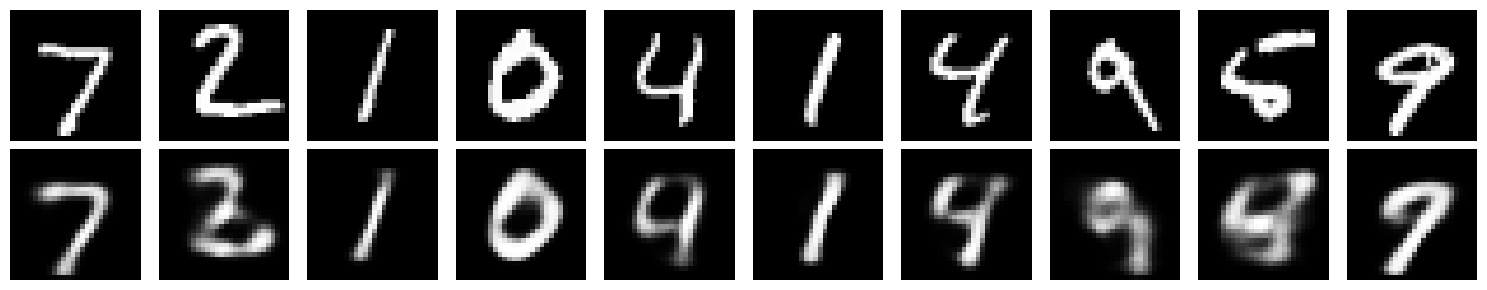

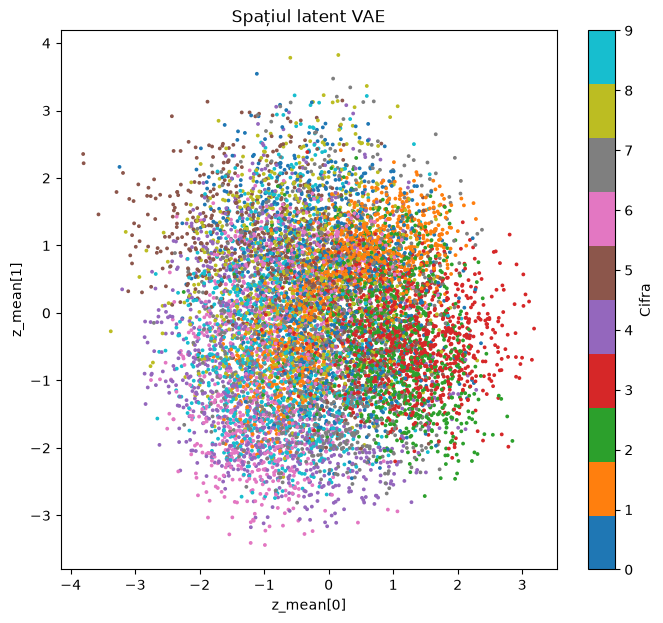

AE test | BCE/pixel=0.092697 | MSE/pixel=0.010086
VAE test | BCE/pixel=0.123725 | MSE/pixel=0.020394 | KL/pixel=0.022018 | total=0.145742


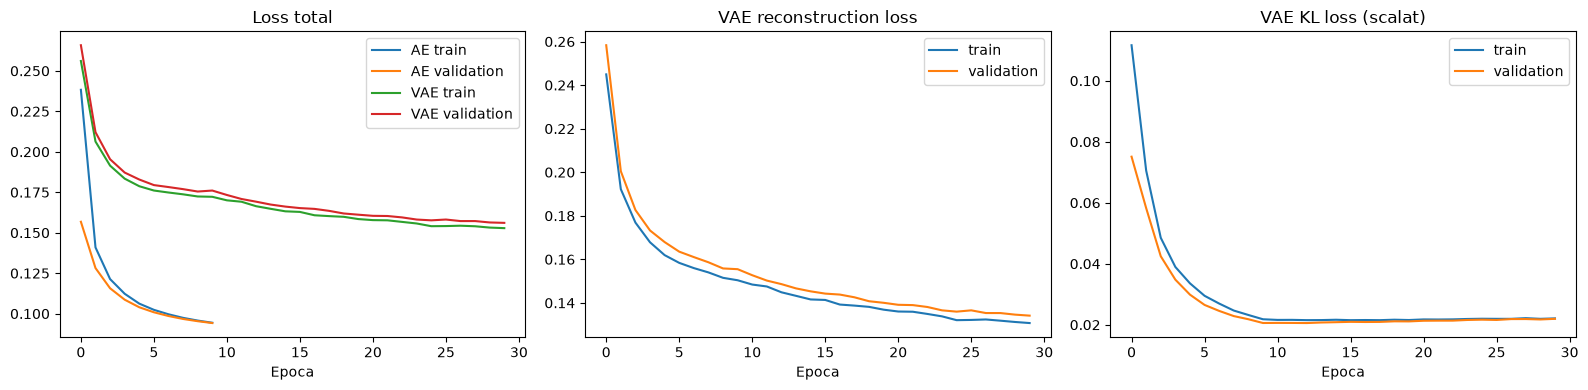

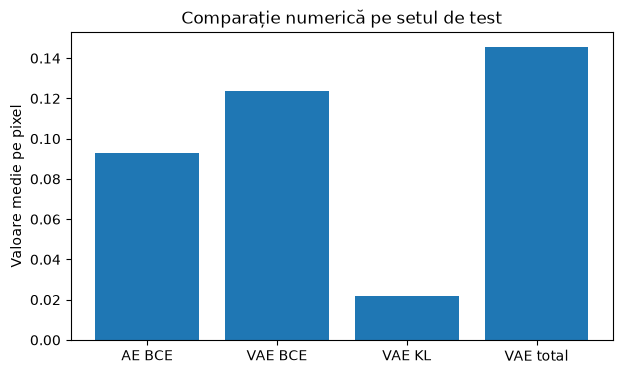

In [6]:
z_mean_test, z_log_var_test, z_test = vae_encoder.predict(X_test_flat, verbose=0)
vae_reconstructed = vae_decoder.predict(z_test, verbose=0)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    axes[0, i].imshow(X_test_flat[i].reshape(28, 28), cmap="gray")
    axes[1, i].imshow(vae_reconstructed[i].reshape(28, 28), cmap="gray")
    axes[0, i].axis("off"); axes[1, i].axis("off")
axes[0, 0].set_ylabel("Original"); axes[1, 0].set_ylabel("VAE")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 7))
scatter = plt.scatter(z_mean_test[:, 0], z_mean_test[:, 1], c=y_test, cmap="tab10", s=3)
plt.colorbar(scatter, ticks=range(10), label="Cifra")
plt.xlabel("z_mean[0]"); plt.ylabel("z_mean[1]"); plt.title("Spațiul latent VAE"); plt.show()

# Evaluare finală pe test; media latentă face comparația reproductibilă.
vae_mean_reconstructed = vae_decoder.predict(z_mean_test, verbose=0)
ae_test_bce = float(np.mean(keras.losses.binary_crossentropy(X_test_flat, ae_reconstructed)))
ae_test_mse = float(np.mean(np.square(X_test_flat - ae_reconstructed)))
vae_test_bce = float(np.mean(keras.losses.binary_crossentropy(X_test_flat, vae_mean_reconstructed)))
vae_test_mse = float(np.mean(np.square(X_test_flat - vae_mean_reconstructed)))
vae_kl_per_example = 0.5 * np.sum(np.square(z_mean_test) + np.exp(z_log_var_test) - 1.0 - z_log_var_test, axis=1)
vae_test_kl = float(np.mean(vae_kl_per_example) / input_dim)
vae_test_total = vae_test_bce + float(vae.beta.numpy()) * vae_test_kl
print(f"AE test | BCE/pixel={ae_test_bce:.6f} | MSE/pixel={ae_test_mse:.6f}")
print(f"VAE test | BCE/pixel={vae_test_bce:.6f} | MSE/pixel={vae_test_mse:.6f} | KL/pixel={vae_test_kl:.6f} | total={vae_test_total:.6f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(history_ae.history["loss"], label="AE train"); axes[0].plot(history_ae.history["val_loss"], label="AE validation")
axes[0].plot(history_vae.history["loss"], label="VAE train"); axes[0].plot(history_vae.history["val_loss"], label="VAE validation"); axes[0].set_title("Loss total")
axes[1].plot(history_vae.history["reconstruction_loss"], label="train"); axes[1].plot(history_vae.history["val_reconstruction_loss"], label="validation"); axes[1].set_title("VAE reconstruction loss")
axes[2].plot(history_vae.history["kl_loss"], label="train"); axes[2].plot(history_vae.history["val_kl_loss"], label="validation"); axes[2].set_title("VAE KL loss (scalat)")
for ax in axes: ax.set_xlabel("Epoca"); ax.legend()
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 4))
plt.bar(["AE BCE", "VAE BCE", "VAE KL", "VAE total"], [ae_test_bce, vae_test_bce, vae_test_kl, vae_test_total])
plt.ylabel("Valoare medie pe pixel"); plt.title("Comparație numerică pe setul de test"); plt.show()

### Generarea unor imagini noi

Deoarece VAE regularizează codul latent către distribuția normală standard, putem eșantiona puncte aleatorii și le putem trimite în decoder.

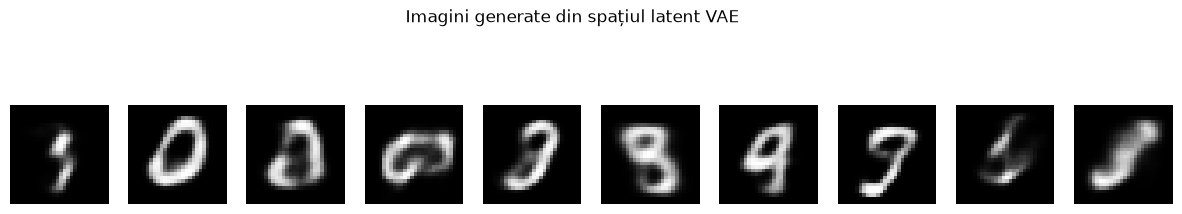

In [7]:
random_latent_vectors = np.random.normal(size=(10, vae_latent_dim))
generated_images = vae_decoder.predict(random_latent_vectors, verbose=0)

plt.figure(figsize=(15, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(generated_images[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
plt.suptitle("Imagini generate din spațiul latent VAE")
plt.show()


## Concluzii, limitări și interpretare matematică

În acest laborator am implementat și comparat un autoencoder simplu și un Variational Autoencoder pentru reconstrucția imaginilor MNIST.

Autoencoderul simplu a învățat să reconstruiască imaginile într-un spațiu latent de 32 de dimensiuni. Pierderea de antrenare a scăzut de la aproximativ **0,2383** în prima epocă la **0,0944** în ultima epocă, iar pierderea de validare a scăzut de la **0,1568** la **0,0942**. Scăderea constantă a ambelor valori și diferența redusă dintre ele indică faptul că modelul a învățat reprezentări utile fără semne evidente de supraînvățare.

VAE-ul a fost antrenat timp de 30 de epoci folosind KL annealing. Parametrul \(\beta\) a crescut gradual de la 0,1 la 1,0 în primele 10 epoci. La final, pe setul de antrenare s-au obținut valorile aproximative **loss = 0,1528**, **reconstruction loss = 0,1307** și **KL loss = 0,0221**. Pe setul de validare, valorile au fost **loss = 0,1561**, **reconstruction loss = 0,1341** și **KL loss = 0,0219**. Diferența mică dintre rezultatele de antrenare și validare indică o generalizare stabilă.

Autoencoderul simplu poate obține o reconstrucție mai precisă, deoarece optimizează în principal eroarea de reconstrucție. VAE-ul are o sarcină mai complexă: minimizează simultan eroarea de reconstrucție și divergența KL, conform relației \(L = L_{rec} + \beta D_{KL}(q_\phi(z|x)||p(z))\). Prin urmare, reconstrucțiile VAE pot fi mai netezite sau mai blurate, dar spațiul latent este mai regulat și poate fi folosit pentru generarea unor imagini noi.

Termenul KL a rămas pozitiv și stabil, în jurul valorii de 0,022, ceea ce arată că modelul utilizează spațiul latent și că nu a apărut un posterior collapse complet. Aplicarea KL annealing a permis modelului să învețe mai întâi reconstrucția și apoi să respecte regularizarea latentă. Totuși, valoarea redusă a termenului KL arată că unele dimensiuni latente pot transporta mai puțină informație decât altele.

Reprezentarea latentă poate fi analizată vizual prin colorarea punctelor după cifra MNIST. Etichetele sunt utilizate numai pentru vizualizare și nu participă la antrenare. Separarea parțială a cifrelor în spațiul latent indică faptul că modelul a învățat anumite caracteristici relevante ale imaginilor.

Evaluarea a fost realizată metodologic corect: validarea a folosit un subset separat extras din setul de antrenare, iar setul de test a fost păstrat pentru evaluarea finală și vizualizări. Limitările experimentului sunt legate de simplitatea setului MNIST, utilizarea unui singur seed și a unui singur split, precum și de faptul că BCE și MSE nu descriu complet calitatea vizuală. Pentru o analiză mai amplă ar fi utile mai multe rulări, dimensiuni latente diferite și compararea unor arhitecturi suplimentare.

În concluzie, autoencoderul simplu este mai potrivit atunci când prioritatea este precizia reconstrucției, iar VAE-ul este mai potrivit pentru obținerea unui spațiu latent probabilistic și generarea de imagini noi.